# Brain Tumor Detection - VGG19 With CNN

import libraries and settings

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# image resize dimensions
image_size = (224, 224)

# batch size
batch_size = 32

# dataset directory (update if needed)
dataset_path = "../dataset_8"

## data augmentation
It was previously noted that rescaling was required. As a result, the training dataset is resized using `flow_from_directory` and enhanced using `ImageDataGenerator`, which allows real-time image augmentation during model training to improve generalization.

In [3]:
train_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=5,          
    width_shift_range=0.05,    
    height_shift_range=0.05,   
    zoom_range=0.1,            
    horizontal_flip=False,     
    vertical_flip=False,       
    fill_mode='nearest'
)

validation_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3
)

VGG19 has more parameters, so it's more prone to overfitting on this small dataset. Therefore, stronger augmentation helps combat this.

In [4]:
training_generator = train_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42  # for reproducibility
)

validation_generator = validation_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42  # for reproducibility
)

Found 480 images belonging to 4 classes.
Found 144 images belonging to 4 classes.


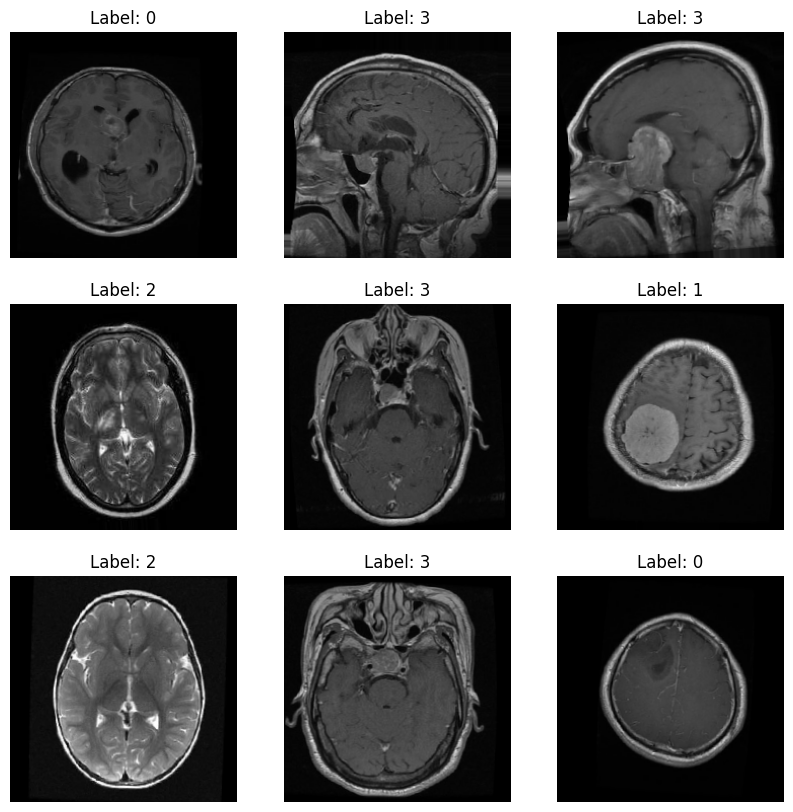

In [5]:
# visualise sample images after data augmentation
images, labels = next(training_generator)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(f"Label: {np.argmax(labels[i])}")
    plt.axis('off')
plt.show()

In [6]:
# load VGG19 without the top classification layers, using imagenet weights
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # freeze the base model

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,448,196 (100.89 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [ ]:
early_stop = EarlyStopping(patience=5, restore_best_weights=True)

# initial training
history = model.fit(
    training_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

c:\Users\user\Desktop\csc3109-ml_project\venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 111s 8s/step - accuracy: 0.2908 - loss: 1.8308 - val_accuracy: 0.5833 - val_loss: 0.9242
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 129s 9s/step - accuracy: 0.6229 - loss: 0.9482 - val_accuracy: 0.6736 - val_loss: 0.7818
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 136s 9s/step - accuracy: 0.6998 - loss: 0.7621 - val_accuracy: 0.7569 - val_loss: 0.6744
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 133s 9s/step - accuracy: 0.7761 - loss: 0.6246 - val_accuracy: 0.7778 - val_loss: 0.6268
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 161s 11s/step - accuracy: 0.7879 - loss: 0.6083 - val_accuracy: 0.8125 - val_loss: 0.5556
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 155s 10s/step - accuracy: 0.8020 - loss: 0.5374 - val_accuracy: 0.8264 - val_loss: 0.4668
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 179s 12s/step - accuracy: 0.8388 - loss: 0.4760 - val_accuracy: 0.8681 - val_loss: 0.4114
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 171s 12s/step - accuracy: 0.8090 - loss: 0.4760 - val_accuracy: 0.8264

- training accuracy and validation accuracy both improve steadily over the epochs, indicating effective learning.
- both training loss and validation loss decrease significantly over time, showing that the model is minimizing the error effectively.
- validation accuracy plateaued and slightly fluctuated after epoch 13, suggesting the model was reaching convergence.
- rarly stopping did not halt training within 20 epochs, indicating no significant overfitting occurred early on.
- validation accuracy consistently follows training accuracy, and validation loss also decreases, suggesting the model generalizes well to unseen data.

In [8]:
# fine-tuning
base_model.trainable = True
model.compile(optimizer=Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history_fine = model.fit(
    training_generator,
    epochs=10,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 364s 24s/step - accuracy: 0.9039 - loss: 0.2368 - val_accuracy: 0.9375 - val_loss: 0.1367
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 425s 29s/step - accuracy: 0.9261 - loss: 0.1662 - val_accuracy: 0.9792 - val_loss: 0.0756
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 486s 33s/step - accuracy: 0.9515 - loss: 0.1213 - val_accuracy: 0.9931 - val_loss: 0.0401
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 424s 28s/step - accuracy: 0.9822 - loss: 0.0739 - val_accuracy: 0.9931 - val_loss: 0.0313
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 366s 25s/step - accuracy: 0.9743 - loss: 0.0737 - val_accuracy: 0.9861 - val_loss: 0.0286
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 365s 24s/step - accuracy: 0.9921 - loss: 0.0446 - val_accuracy: 1.0000 - val_loss: 0.0129
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 364s 24s/step - accuracy: 0.9853 - loss: 0.0530 - val_accuracy: 0.9861 - val_loss: 0.0282
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 369s 25s/step - accuracy: 0.9865 - loss: 0.0513 - val_accuracy: 0.

- fine-tuning with a small learning rate significantly boosts performance.
- validation accuracy peaked at 100% (epoch 6).
- validation loss reduced to as low as 0.0116, reflecting highly confident predictions.
- the training accuracy approached near-perfect levels (~99%), with correspondingly low training loss.
- slight fluctuations after epoch 6 are typical in fine-tuning but performance remained exceptionally high.
- no immediate signs of severe overfitting observed due to consistent validation performance.



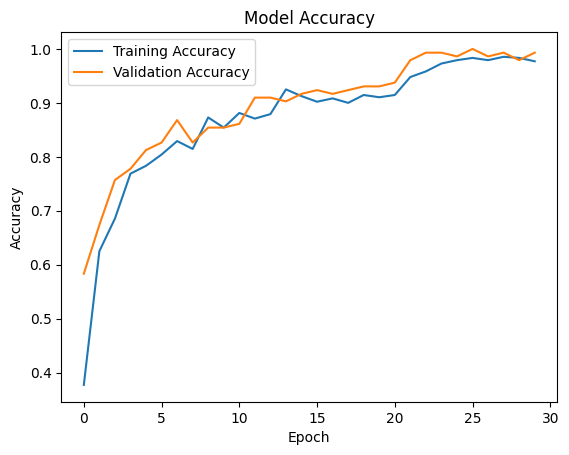

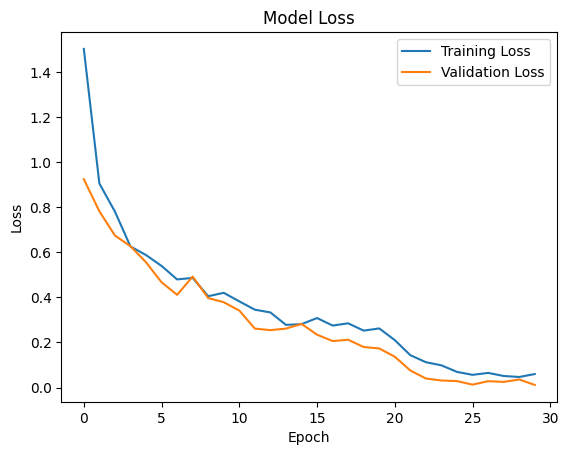

In [9]:
# plot accuracy
plt.plot(history.history['accuracy'] + history_fine.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'] + history_fine.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# plot loss
plt.plot(history.history['loss'] + history_fine.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'] + history_fine.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### model accuracy observations

- training accuracy and validation accuracy both show a strong upward trend, reaching approximately 98-99% towards the final epochs.
- notably, validation accuracy consistently tracks or slightly exceeds training accuracy.
- this shows that the model generalizes well to unseen validation data.
- overfitting is not evident, as the validation curve does not degrade or diverge significantly from the training curve.

### model loss observations

- training loss steadily decreases, approaching near zero (~0.01) by the end of training.
- validation loss also follows a similar decreasing pattern, with its final values approaching zero.
- there is a  consistent decline of both loss curves, with minimal gap between them.
- this means that the model is learning effectively, with no major signs of overfitting or underfitting.

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# get class labels
class_labels = list(validation_generator.class_indices.keys())

# predict on validation data
y_true = []
y_pred = []

# since validation_generator has shuffle=False, order is preserved
for images, labels in validation_generator:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels, axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

    # stop when all validation data is covered
    if len(y_true) >= validation_generator.samples:
        break


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


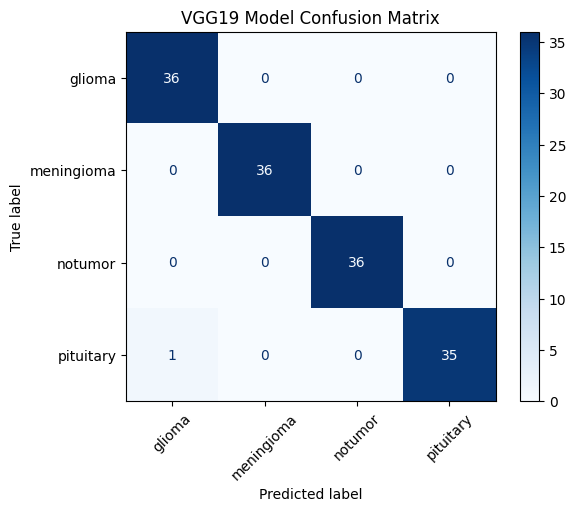

In [ ]:
# convert to numpy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Generate Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("VGG19 Model Confusion Matrix")
plt.show()

### observations

- the model achieved perfect classification for glioma, meningioma, and no tumor classes with no misclassifications.
- only one instance of pituitary tumor was misclassified as glioma.
- overall, this indicates exceptionally high classification performance, with only a single error out of 144 samples, translating to a raw accuracy of approximately 99.31%.


In [ ]:
model.save('final_vgg19_model.h5')

In [ ]:
# double check: print model summary to confirm lmodel has been saved correctly

from tensorflow.keras.models import load_model

model = load_model('final_vgg19_model.h5')

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,448,198 (100.89 MB)

 Trainable params: 26,448,196 (100.89 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

## fine-tuning the model's hyperparameters (did not use in the end...)



In [11]:
import keras_tuner as kt
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

def build_model(hp):
    base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False  # freeze during tuning

    model = Sequential()
    model.add(base_model)
    model.add(Flatten())
    
    # Tune number of Dense units
    units = hp.Int('units', min_value=128, max_value=512, step=64)
    model.add(Dense(units, activation='relu'))
    
    # Tune dropout rate
    dropout_rate = hp.Float('dropout', min_value=0.3, max_value=0.7, step=0.1)
    model.add(Dropout(dropout_rate))
    
    model.add(Dense(4, activation='softmax'))

    # Tune learning rate
    learning_rate = hp.Choice('learning_rate', values=[1e-4, 5e-4, 1e-3])

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    
    return model

ModuleNotFoundError: No module named 'keras_tuner'

initialise tuner

In [ ]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,
    directory='keras_tuner_vgg19',
    project_name='brain_mri_tuning'
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

tuner.search(
    training_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

# fine-tuning: unfreeze base_model
best_model.layers[0].trainable = True

# compile with a smaller learning rate for fine-tuning
best_model.compile(optimizer=Adam(learning_rate=1e-5),
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

# fine-tune
history_fine = best_model.fit(
    training_generator,
    epochs=10,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

In [ ]:
best_hps = tuner.get_best_hyperparameters(1)[0]
print(f"Best units: {best_hps.get('units')}")
print(f"Best dropout: {best_hps.get('dropout')}")
print(f"Best learning rate: {best_hps.get('learning_rate')}")